#  Исследование результатов А/В-теста и поиск инсайтов

**Автор:** Лагода Максим
**Дата:** 18.07.2026

SollmaFin — международное мобильное приложение для онлайн-торговли финансовыми активами. Пользователи могут инвестировать деньги в акции, валюту, криптовалюту, биржевые фонды (ETF) и другие активы. Целевая аудитория приложения — начинающие инвесторы. Получить доступ к финансовым рынкам можно со смартфона либо через веб-версию. 

Приложение ориентировано на рынок Латинской Америки с акцентом на четыре страны: Мексику, Бразилию, Колумбию и Аргентину — там быстро растёт интерес к финтеху и инвестициям, а экономики очень разные. 

Появилась гипотеза о недостаточной финансовой грамотности пользователей: они не понимают, как работать с активами разной степени риска. Клиенты покупают активы с высоким риском и теряют деньги, что снижает вовлечённость.
Команда продукта решила обновить онбординг пользователей и добавить в него детальную информацию о различиях финансовых активов и связанных с ними рисках. Однако появилось опасение, что углублённый онбординг отпугнёт клиентов от пополнения депозита и более рискованных вложений. 

Чтобы разобраться, команда решила провести A/B-эксперимент. 

### А/В-эксперимент

В эксперименте участвовали новые пользователи, которые зарегистрировались в приложении со 2 по 15 июня 2025 года. 
Пользователей случайным образом разделили на две равные группы: 
- Контрольная группа проходила стандартный онбординг без обязательного обучения.
- Тестовая группа проходила обновлённый онбординг с подробной информацией об активах и связанных с ними рисках. 

После разделения активность пользователей анализировали в течение недели.

Цель эксперимента — оценить, как обновлённый онбординг влияет на поведение пользователей и их дальнейшую инвестиционную активность.

При внедрении новой фичи команда продукта выдвинула такие гипотезы:
- Гипотеза роста: обучающий онбординг помогает пользователям лучше понимать принципы инвестирования, поэтому они будут чаще открывать второй депозит.
- Гипотеза риска: информация о возможных потерях и высоких рисках отпугнёт некоторых новичков, особенно самых осторожных, что снизит конверсию в первый депозит.
- Дополнительная гипотеза: после нового онбординга пользователи, которые выбрали высокорискованные активы, будут чаще, чем раньше, возвращаться и открывать второй депозит. При старом онбординге пользователи часто покупали активы с высоким риском без понимания последствий. Это приводило к потерям и оттоку после первого депозита. 

Чтобы увидеть полную картину, недостаточно следить за метриками конверсии. Команда выбрала для эксперимента такой набор метрик: 
- Ключевая метрика — средняя сумма всех депозитов на одного пользователя (включая тех, кто установил приложение или открыл веб-версию).
- Барьерная метрика — конверсия из регистрации в первый депозит.
- Вспомогательная метрика 1 — конверсия из первого депозита во второй.
- Вспомогательная метрика 2 — средняя сумма всех депозитов на пользователя, который открыл хотя бы один депозит.

Ожидалось, что ключевая и барьерная метрики не упадут, а вспомогательные покажут значительный рост. 

### Задачи аналитика

Вам предстоит провести полный анализ результатов А/В-эксперимента. Но перед этим нужно погрузиться в продукт и изучить исторические данные.    


#### 1. Анализ исторических данных

Чтобы понять, для чего была разработана новая фича, вам предстоит изучить исторические данные: 
- Поведение новых пользователей, в том числе динамику привлечения, сегментацию и ключевые этапы воронки действий.
- Метрики, связанные с внесением депозитов, в том числе средние суммы депозитов. 

#### 2. Анализ данных А/В-теста

Изучение результатов эксперимента будет состоять из двух этапов: 
- Сравнение поведения пользователей в контрольной и тестовой группах, оценка статистической значимости изменений. 
- Исследование влияния нового онбординга на поведение платящих пользователей. В исследовании вы будете использовать бутстрап и сосредоточитесь на нижних и верхних перцентилях распределения депозитов. 
- Такой подход позволит понять, как обновлённый онбординг повлиял на ключевые бизнес-метрики, найти точки роста и сформулировать рекомендации по улучшению пользовательского опыта и монетизации.


### Данные

Вы будете работать с двумя датасетами:  

1. Датасет `/datasets/pa_sollmafin_hist.csv` содержит исторические данные о ключевых действиях новых пользователей, привлечённых в период с 1 апреля по 1 июня 2025 года включительно. В датасете собраны действия пользователей до оформления второго депозита. 
2. Датасет `/datasets/pa_sollmafin_abt.csv` содержит данные А/В-эксперимента — все действия новых пользователей, которые зарегистрировались со 2 по 15 июня 2025 года включительно. Данные собраны в рамках проверки гипотезы о влиянии нового онбординга на поведение и активность пользователей. Пользователи уже распределены по группам А/В-эксперимента.

Общие поля датасетов:
- `user_id` — уникальный идентификатор пользователя;
- `country_code` — код страны пользователя в формате ISO (например, `BR` — Бразилия, `MX` — Мексика, `AR` — Аргентина, `CO` — Колумбия);
- `platform` — устройство, с которого пользователь взаимодействует с продуктом: mobile или web;
- `first_ts` — время первого появления пользователя в системе;
- `first_dt` — дата первого появления пользователя (без времени);
- `event_ts` — время события;
- `event_name` — название события;
- `amount` — сумма пополнения депозита;
- `asset` — тип приобретённого актива; 
- `risk_level` — уровень риска актива: low — низкий риск, medium — средний риск, high — высокий риск.

В датасете `/datasets/pa_sollmafin_abt.csv` содержатся два дополнительных поля:
- `ab_test` — название А/В-эксперимента;
- `group` — пользовательская группа А/В-эксперимента.


### План проекта
1. Загрузка исторических данных и их предобработка
2. Исследовательский анализ исторических данных
3. Исследование результатов А/В эксперимента
4. Анализ изменений суммы депозитов на платящего пользователя
5. Выводы

---

## Часть 1

### 1. Загрузка исторических данных и их предобработка

Загрузите данные из датасета `/datasets/pa_sollmafin_hist.csv` и получите основную информацию о них. Проведите предобработку. Зафиксируйте основную информацию о данных и предобработке в кратком промежуточном выводе.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import ttest_ind

In [4]:
# Загрузка данных
sollmafin_hist = pd.read_csv('https://code.s3.yandex.net/datasets/pa_sollmafin_hist.csv')

In [5]:
# Описание данных sollmafin_hist
print("Первые 5 строк sollmafin_hist:")
display(sollmafin_hist.head())

print("\nИнформация о данных sollmafin_hist:")
sollmafin_hist.info()

print("\nПропуски sollmafin_hist:")
print(sollmafin_hist.isna().sum())

print("\nПолные дубликаты строк sollmafin_hist:")
print(sollmafin_hist.duplicated().sum())

Первые 5 строк sollmafin_hist:


,user_id,country_code,platform,first_ts,first_dt,event_ts,event_name,amount,asset,risk_level
0,548ac59f-656d-4110-80d2-49f0a217f08a,BR,mobile,2025-04-02 19:55:51,2025-04-02,2025-04-02 19:55:51,install / open_web,NaN,NaN,NaN
1,548ac59f-656d-4110-80d2-49f0a217f08a,BR,mobile,2025-04-02 19:55:51,2025-04-02,2025-04-02 19:55:59,introduction,NaN,NaN,NaN
2,548ac59f-656d-4110-80d2-49f0a217f08a,BR,mobile,2025-04-02 19:55:51,2025-04-02,2025-04-02 23:46:06,registration,NaN,NaN,NaN
3,548ac59f-656d-4110-80d2-49f0a217f08a,BR,mobile,2025-04-02 19:55:51,2025-04-02,2025-04-02 23:46:15,main_page,NaN,NaN,NaN
4,548ac59f-656d-4110-80d2-49f0a217f08a,BR,mobile,2025-04-02 19:55:51,2025-04-02,2025-04-02 23:47:59,onboarding_complete,NaN,NaN,NaN



Информация о данных sollmafin_hist:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 238059 entries, 0 to 238058
Data columns (total 10 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   user_id       238059 non-null  object 
 1   country_code  238059 non-null  object 
 2   platform      238059 non-null  object 
 3   first_ts      238059 non-null  object 
 4   first_dt      238059 non-null  object 
 5   event_ts      238059 non-null  object 
 6   event_name    238059 non-null  object 
 7   amount        33093 non-null   float64
 8   asset         15392 non-null   object 
 9   risk_level    15392 non-null   object 
dtypes: float64(1), object(9)
memory usage: 18.2+ MB

Пропуски sollmafin_hist:
user_id              0
country_code         0
platform             0
first_ts             0
first_dt             0
event_ts             0
event_name           0
amount          204966
asset           222667
risk_level      222667
dtype: int64

П

In [6]:
# Преобразование ячеек с датами sollmafin_hist
sollmafin_hist['first_ts'] = pd.to_datetime(sollmafin_hist['first_ts'])
sollmafin_hist['first_dt'] = pd.to_datetime(sollmafin_hist['first_dt'])
sollmafin_hist['event_ts'] = pd.to_datetime(sollmafin_hist['event_ts'])

In [7]:
# Количество уникальных пользователей
print(f"Уникальных пользователей в sollmafin_hist: {sollmafin_hist['user_id'].nunique()}")

# Уникальные события
print("\nСобытия в sollmafin_hist:", sollmafin_hist['event_name'].unique())

# Проверка дат
print("\nДиапазон дат sollmafin_hist:", sollmafin_hist['first_dt'].min(), "-", sollmafin_hist['first_dt'].max())

# Проверка: event_ts >= first_ts
print("\nСобытий до first_ts в sollmafin_hist:", (sollmafin_hist['event_ts'] < sollmafin_hist['first_ts']).sum())

Уникальных пользователей в sollmafin_hist: 41032

События в sollmafin_hist: ['install / open_web' 'introduction' 'registration' 'main_page'
 'onboarding_complete' 'first_deposit' 'asset_purchase' 'second_deposit']

Диапазон дат sollmafin_hist: 2025-04-01 00:00:00 - 2025-06-01 00:00:00

Событий до first_ts в sollmafin_hist: 0


**Выводы**
- Данные загружены успешно, пропуски логичны (amount заполнен только для депозитов, asset/risk_level - только для покупок активов).
- Дубликатов нет, типы данных приведены корректно.
- Временные метки сконвертированы в datetime.
- Периоды данных соответствуют ожидаемым (исторические: апрель-май 2025, экспериментальные: июнь 2025).

---

### 2. Исследовательский анализ исторических данных

Проведите исследовательский анализ исторических данных. По каждой подзадаче сделайте промежуточный вывод. 

**Задача 2.1.** Анализ новых пользователей.
- Изучите динамику привлечения новых пользователей в приложение.

count     62.000000
mean     661.806452
std       23.425388
min      613.000000
25%      646.500000
50%      663.000000
75%      682.750000
max      713.000000
Name: new_users, dtype: float64


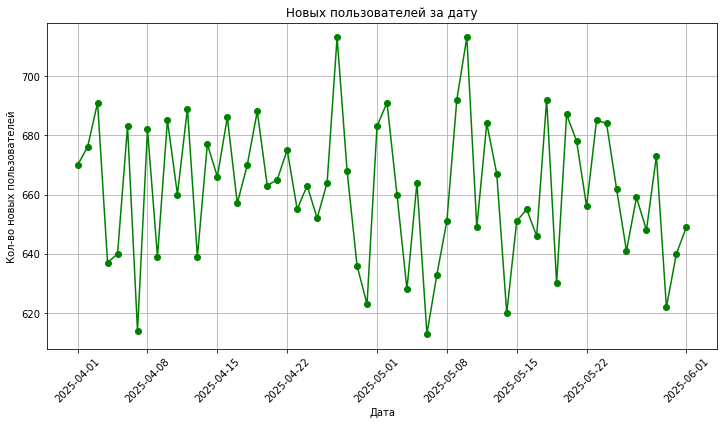

In [8]:
sollmafin_hist_new_users = sollmafin_hist.groupby('first_dt')['user_id'].nunique().reset_index(name='new_users')

print(sollmafin_hist_new_users['new_users'].describe())

plt.figure(figsize=(12, 6))
plt.plot(sollmafin_hist_new_users['first_dt'], sollmafin_hist_new_users['new_users'], 'o-', color='green')
plt.xlabel('Дата')
plt.ylabel('Кол-во новых пользователей')
plt.title('Новых пользователей за дату')
plt.grid(True)
plt.xticks(rotation=45)
plt.show()

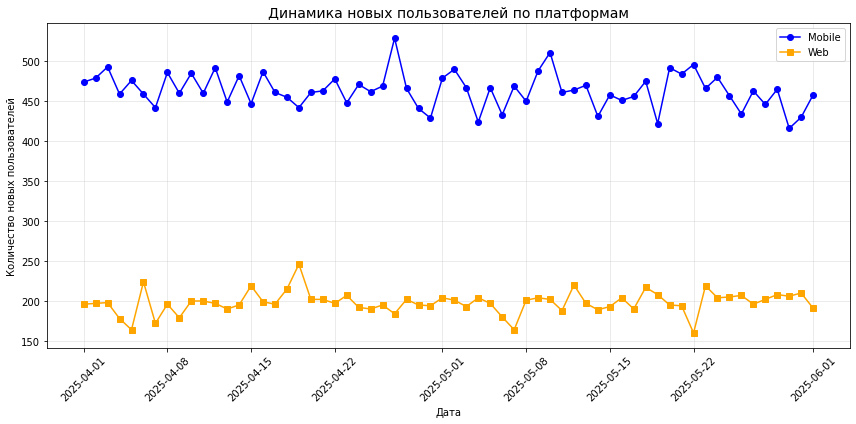

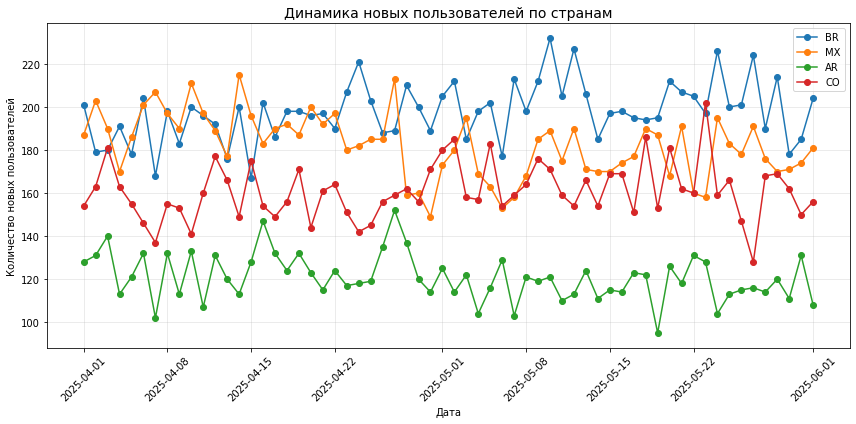

In [9]:
# Динамика новых пользователей по платформам
platform_by_date = sollmafin_hist.groupby(['first_dt', 'platform'])['user_id'].nunique().unstack()

plt.figure(figsize=(12,6))
plt.plot(platform_by_date.index, platform_by_date['mobile'], 'o-', label='Mobile', color='blue')
plt.plot(platform_by_date.index, platform_by_date['web'], 's-', label='Web', color='orange')
plt.xlabel('Дата')
plt.ylabel('Количество новых пользователей')
plt.title('Динамика новых пользователей по платформам', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Динамика новых пользователей по странам
country_by_date = sollmafin_hist.groupby(['first_dt', 'country_code'])['user_id'].nunique().unstack()

plt.figure(figsize=(12,6))
for country in ['BR', 'MX', 'AR', 'CO']:
    plt.plot(country_by_date.index, country_by_date[country], 'o-', label=country)
plt.xlabel('Дата')
plt.ylabel('Количество новых пользователей')
plt.title('Динамика новых пользователей по странам', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Выводы**
- Среднее количество новых пользователей в день: 662 человека.
- Стандартное отклонение: 23 человека (~3.5% от среднего).
- Mobile и Бразилия - ключевые каналы привлечения
- Приток стабильный, без аномалий, период репрезентативен для анализа.

**Задача 2.2.** Анализ воронок событий.
- Постройте классическую и пошаговую воронки;
- Охарактеризуйте пользовательский путь в приложении и определите узкие места воронки. 


,step,users,conversion_from_first_%,conversion_from_previous_%
0,install / open_web,41032,100.0,NaN
1,introduction,41032,100.0,100.0
2,registration,38133,92.9,92.9
3,main_page,35040,85.4,91.9
4,onboarding_complete,34337,83.7,98.0
5,first_deposit,27685,67.5,80.6
6,asset_purchase,15392,37.5,55.6
7,second_deposit,5408,13.2,35.1


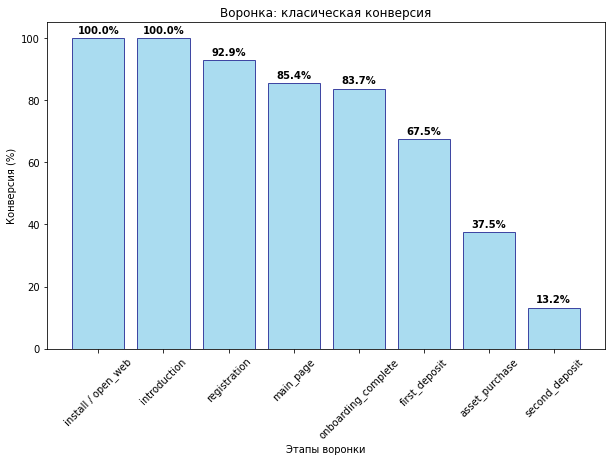

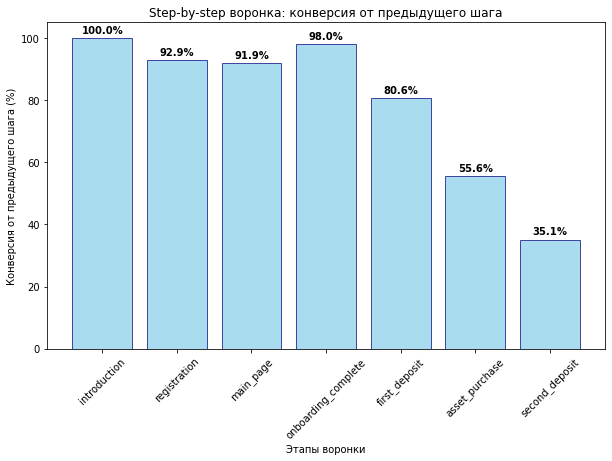

In [10]:
funnel_steps = ['install / open_web', 'introduction', 'registration', 'main_page', 'onboarding_complete', 'first_deposit', 'asset_purchase', 'second_deposit']

# Считаем количество уникальных пользователей на каждом шаге
funnel_counts = sollmafin_hist.groupby('event_name')['user_id'].nunique().reindex(funnel_steps)

# Создаём DataFrame
funnel_hist_data = pd.DataFrame({
    'step': funnel_counts.index,
    'users': funnel_counts.values
})

# Берём количество пользователей на первом шаге
first_step_users = funnel_hist_data['users'].iloc[0]

# Конверсия от первого шага
funnel_hist_data['conversion_from_first_%'] = (funnel_hist_data['users'] / first_step_users * 100).round(1)

# Конверсия от предыдущего шага
funnel_hist_data['conversion_from_previous_%'] = (funnel_hist_data['users'] / funnel_hist_data['users'].shift(1) * 100).round(1)

display(funnel_hist_data.head(10))

# Визуализация класической воронки
plt.figure(figsize=(10, 6))

steps_for_plot = funnel_hist_data['step']
conversions = funnel_hist_data['conversion_from_first_%']

plt.bar(steps_for_plot, conversions, color='skyblue', edgecolor='navy', alpha=0.7)

for i, (step, conv) in enumerate(zip(steps_for_plot, conversions)):
    plt.text(i, conv + 1, f'{conv:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title('Воронка: класическая конверсия')
plt.ylabel('Конверсия (%)')
plt.xlabel('Этапы воронки')
plt.xticks(rotation=45)
plt.show()

# Визуализация Step-by-step воронки
plt.figure(figsize=(10, 6))

steps_for_plot = funnel_hist_data['step'].iloc[1:]
conversions = funnel_hist_data['conversion_from_previous_%'].iloc[1:]

plt.bar(steps_for_plot, conversions, color='skyblue', edgecolor='navy', alpha=0.7)

for i, (step, conv) in enumerate(zip(steps_for_plot, conversions)):
    plt.text(i, conv + 1, f'{conv:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title('Step-by-step воронка: конверсия от предыдущего шага')
plt.ylabel('Конверсия от предыдущего шага (%)')
plt.xlabel('Этапы воронки')
plt.xticks(rotation=45)
plt.show()

,step,users,conversion_from_first_%,conversion_from_previous_%
0,install / open_web,28758,100.0,NaN
1,introduction,28758,100.0,100.0
2,registration,26721,92.9,92.9
3,main_page,24509,85.2,91.7
4,onboarding_complete,24008,83.5,98.0
5,first_deposit,19372,67.4,80.7
6,second_deposit,3809,13.2,19.7


,step,users,conversion_from_first_%,conversion_from_previous_%
0,install / open_web,12274,100.0,NaN
1,introduction,12274,100.0,100.0
2,registration,11412,93.0,93.0
3,main_page,10531,85.8,92.3
4,onboarding_complete,10329,84.2,98.1
5,first_deposit,8313,67.7,80.5
6,second_deposit,1599,13.0,19.2


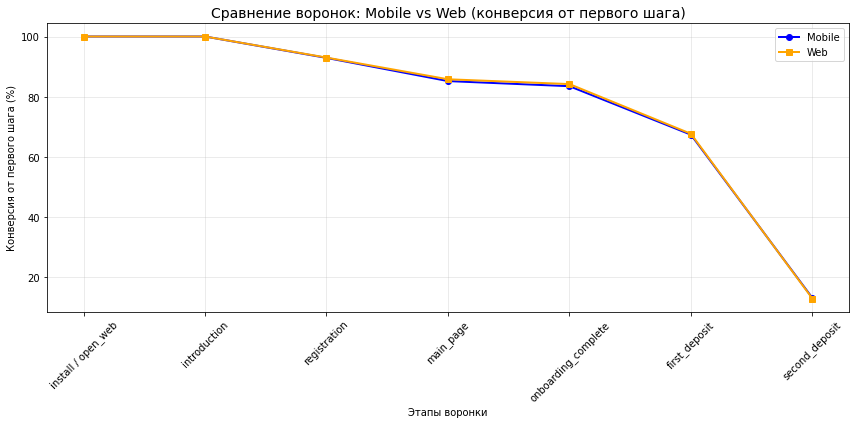

,step,users,conversion_from_first_%,conversion_from_previous_%
0,install / open_web,12266,100.0,NaN
1,introduction,12266,100.0,100.0
2,registration,11382,92.8,92.8
3,main_page,10447,85.2,91.8
4,onboarding_complete,10247,83.5,98.1
5,first_deposit,8272,67.4,80.7
6,second_deposit,1585,12.9,19.2


,step,users,conversion_from_first_%,conversion_from_previous_%
0,install / open_web,11303,100.0,NaN
1,introduction,11303,100.0,100.0
2,registration,10511,93.0,93.0
3,main_page,9599,84.9,91.3
4,onboarding_complete,9403,83.2,98.0
5,first_deposit,7600,67.2,80.8
6,second_deposit,1516,13.4,19.9


,step,users,conversion_from_first_%,conversion_from_previous_%
0,install / open_web,7489,100.0,NaN
1,introduction,7489,100.0,100.0
2,registration,6997,93.4,93.4
3,main_page,6480,86.5,92.6
4,onboarding_complete,6345,84.7,97.9
5,first_deposit,5072,67.7,79.9
6,second_deposit,1018,13.6,20.1


,step,users,conversion_from_first_%,conversion_from_previous_%
0,install / open_web,9974,100.0,NaN
1,introduction,9974,100.0,100.0
2,registration,9243,92.7,92.7
3,main_page,8514,85.4,92.1
4,onboarding_complete,8342,83.6,98.0
5,first_deposit,6741,67.6,80.8
6,second_deposit,1289,12.9,19.1


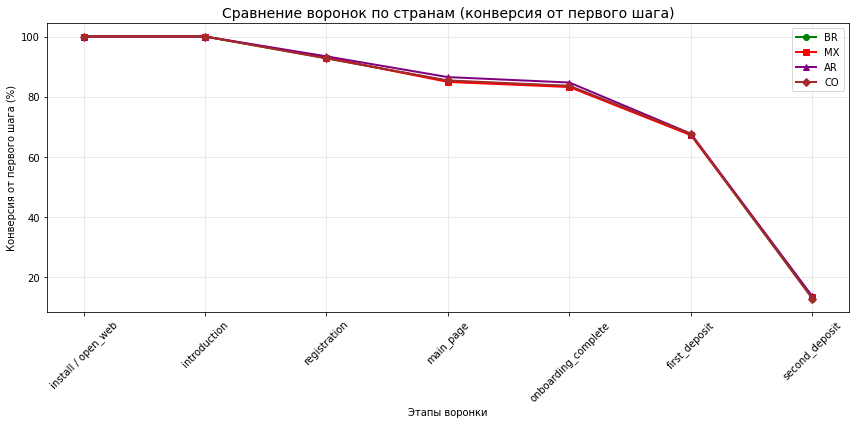

In [11]:
def build_funnel_by_segment(df, segment_col, segment_value):
    
    segment_df = df[df[segment_col] == segment_value]
    
    funnel_steps = ['install / open_web', 'introduction', 'registration', 'main_page', 
                   'onboarding_complete', 'first_deposit', 'second_deposit']
    
    counts = []
    for step in funnel_steps:
        users = segment_df[segment_df['event_name'] == step]['user_id'].nunique()
        counts.append(users)
    
    funnel_data = pd.DataFrame({
        'step': funnel_steps,
        'users': counts
    })
    
    first_step_users = funnel_data['users'].iloc[0]
    funnel_data['conversion_from_first_%'] = (funnel_data['users'] / first_step_users * 100).round(1)
    funnel_data['conversion_from_previous_%'] = (funnel_data['users'] / funnel_data['users'].shift(1) * 100).round(1)
    
    return funnel_data

funnel_mobile = build_funnel_by_segment(sollmafin_hist, 'platform', 'mobile')
funnel_web = build_funnel_by_segment(sollmafin_hist, 'platform', 'web')

funnel_br = build_funnel_by_segment(sollmafin_hist, 'country_code', 'BR')
funnel_mx = build_funnel_by_segment(sollmafin_hist, 'country_code', 'MX')
funnel_ar = build_funnel_by_segment(sollmafin_hist, 'country_code', 'AR')
funnel_co = build_funnel_by_segment(sollmafin_hist, 'country_code', 'CO')

# Воронки по платформам
display(funnel_mobile)
display(funnel_web)

# Визуализация
plt.figure(figsize=(12,6))
plt.plot(funnel_mobile['step'], funnel_mobile['conversion_from_first_%'], 'o-', label='Mobile', color='blue', linewidth=2)
plt.plot(funnel_web['step'], funnel_web['conversion_from_first_%'], 's-', label='Web', color='orange', linewidth=2)
plt.title('Сравнение воронок: Mobile vs Web (конверсия от первого шага)', fontsize=14)
plt.xlabel('Этапы воронки')
plt.ylabel('Конверсия от первого шага (%)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Воронки по странам
for country in ['BR', 'MX', 'AR', 'CO']:
    display(build_funnel_by_segment(sollmafin_hist, 'country_code', country))
    
    # Визуализация
plt.figure(figsize=(12,6))
plt.plot(funnel_br['step'], funnel_br['conversion_from_first_%'], 'o-', label='BR', color='green', linewidth=2)
plt.plot(funnel_mx['step'], funnel_mx['conversion_from_first_%'], 's-', label='MX', color='red', linewidth=2)
plt.plot(funnel_ar['step'], funnel_ar['conversion_from_first_%'], '^-', label='AR', color='purple', linewidth=2)
plt.plot(funnel_co['step'], funnel_co['conversion_from_first_%'], 'D-', label='CO', color='brown', linewidth=2)
plt.title('Сравнение воронок по странам (конверсия от первого шага)', fontsize=14)
plt.xlabel('Этапы воронки')
plt.ylabel('Конверсия от первого шага (%)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Выводы**
- Основные узкие места воронки:
   - onboarding_complete - first_deposit: потеря 19.4% (конверсия 80.6%)
   - first_deposit - second_deposit: потеря 64.9% (конверсия 35.1%) - критическое узкое место.
- Покупка активов (asset_purchase): только 55.6% платящих покупают активы.
- Проблема: пользователи делают первый депозит, но не инвестируют, теряют интерес и не возвращаются.
- Сегментный анализ не выявил необходимости в персонализации по платформам или странам

**Задача 2.3.** Влияние уровня риска актива на открытие второго депозита.
- Изучите, как уровень риска первого актива влияет на конверсию во второй депозит.  

In [12]:
# Находим первую покупку актива для каждого пользователя
first_asset = (sollmafin_hist[sollmafin_hist['event_name'] == 'asset_purchase']
               .sort_values('event_ts') # сортируем по дате 
               .drop_duplicates('user_id', keep='first') # оставляем только первую покупку
               [['user_id', 'risk_level']])

# Находим пользователей со вторым депозитом
second_deposit_users = (sollmafin_hist[sollmafin_hist['event_name'] == 'second_deposit']['user_id'].unique())

# Добавляем флаг наличия второго депозита
first_asset['has_second_deposit'] = first_asset['user_id'].isin(second_deposit_users)

# Группируем по уровню риска
conversion_by_risk = first_asset.groupby('risk_level').agg(
    total_users=('user_id', 'count'),
    users_with_second=('has_second_deposit', 'sum')
)
conversion_by_risk['conversion_%'] = (conversion_by_risk['users_with_second'] / conversion_by_risk['total_users'] * 100).round(1)

display(conversion_by_risk)

,total_users,users_with_second,conversion_%
risk_level,,,
high,7740,2040,26.4
low,2327,1080,46.4
medium,5325,2288,43.0


**Выводы**
- Конверсия во второй депозит для разных уровней риска:
   - Low: 46.4%
   - Medium: 43.0%
   - High: 26.4% (самая низкая)
- 50.3% пользователей впервые выбирают high-risk активы.
- Вывод: пользователи не понимают рисков, выбирают высокорисковые активы, теряют деньги и не возвращаются.

**Задача 2.4.** Анализ ключевой метрики на исторических данных.
- На исторических данных рассчитайте значение ключевой метрики — средней суммы всех депозитов на одного пользователя. Учитывайте всех пользователей, которые взаимодействовали с сервисом. Это позволит зафиксировать базовый уровень монетизации.
- Визуализируйте данные, где необходимо. По результатам исследовательского анализа сделайте краткий вывод. 

In [13]:
# Общее количество пользователей
total_users = sollmafin_hist['user_id'].nunique()

# Сумма всех депозитов (first_deposit + second_deposit)
deposit_sum = sollmafin_hist[sollmafin_hist['event_name'].isin(['first_deposit', 'second_deposit'])]['amount'].sum()

# Ключевая метрика
key_metric = deposit_sum / total_users

print(f"Всего пользователей: {total_users}")
print(f"Сумма всех депозитов: {deposit_sum:,.2f}")
print(f"Средняя сумма депозитов на пользователя: {key_metric:.2f}")

Всего пользователей: 41032
Сумма всех депозитов: 3,756,981.00
Средняя сумма депозитов на пользователя: 91.56


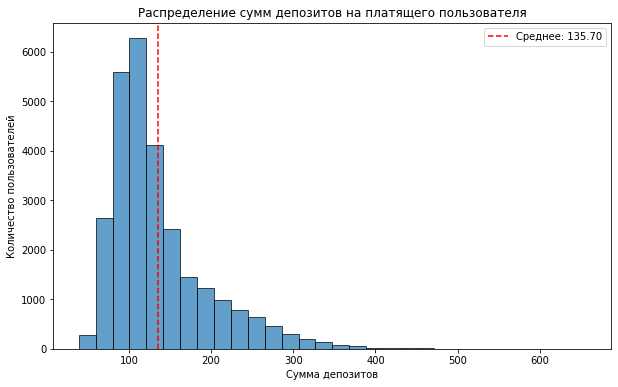

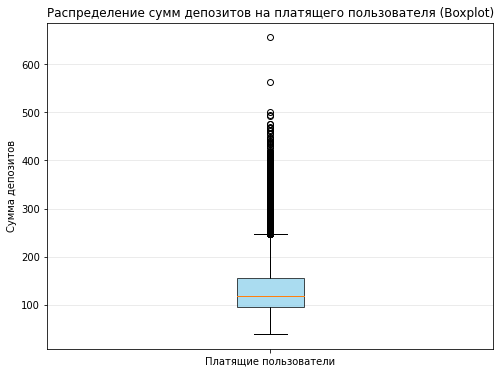

Количество платящих пользователей: 27685
Среднее: 135.70
Медиана: 118.00
25-й перцентиль: 95.00
75-й перцентиль: 156.00
Максимум: 656.00
Минимум: 39.00
Стандартное отклонение: 59.90


In [14]:
# Собираем суммы депозитов по пользователям
user_deposits = sollmafin_hist[sollmafin_hist['event_name'].isin(['first_deposit', 'second_deposit'])].groupby('user_id')['amount'].sum()

# Гистограмма
plt.figure(figsize=(10,6))
plt.hist(user_deposits, bins=30, edgecolor='black', alpha=0.7)
plt.axvline(user_deposits.mean(), color='red', linestyle='--', label=f'Среднее: {user_deposits.mean():.2f}')
plt.xlabel('Сумма депозитов')
plt.ylabel('Количество пользователей')
plt.title('Распределение сумм депозитов на платящего пользователя')
plt.legend()
plt.show()

# Boxplot
plt.figure(figsize=(8,6))
plt.boxplot(user_deposits, vert=True, patch_artist=True, 
            boxprops=dict(facecolor='skyblue', alpha=0.7))
plt.ylabel('Сумма депозитов')
plt.title('Распределение сумм депозитов на платящего пользователя (Boxplot)')
plt.xticks([1], ['Платящие пользователи'])
plt.grid(axis='y', alpha=0.3)
plt.show()

# Добавим текстовую информацию
mean_val = user_deposits.mean()
median_val = user_deposits.median()
q25 = user_deposits.quantile(0.25)
q75 = user_deposits.quantile(0.75)
std_dev = user_deposits.std() # стандартное отклонение

print(f"Количество платящих пользователей: {len(user_deposits)}")
print(f"Среднее: {mean_val:.2f}")
print(f"Медиана: {median_val:.2f}")
print(f"25-й перцентиль: {q25:.2f}")
print(f"75-й перцентиль: {q75:.2f}")
print(f"Максимум: {user_deposits.max():.2f}")
print(f"Минимум: {user_deposits.min():.2f}")
print(f"Стандартное отклонение: {std_dev:.2f}")

**Выводы**
- Ключевая метрика (средняя сумма депозитов на всех пользователей): 91.56
- Вспомогательная метрика 2 (средняя сумма на платящего): 135.70
- Медиана: 118.00, 25-й перцентиль: 95.00, 75-й перцентиль: 156.00
- Распределение скошено вправо - есть небольшое количество пользователей с крупными депозитами.
- Высокое стандартное отклонение (59.90) указывает на значительный разброс сумм депозитов и наличие выбросов.

---

## Часть 2

### 3. Исследование результатов А/В эксперимента
Загрузите данные с результатами эксперимента (датасет `/datasets/pa_sollmafin_abt.csv `). Проверьте корректность данных и проведите предобработку. Зафиксируйте основную информацию о данных и предобработке в кратком промежуточном выводе.
Затем проведите анализ результатов А/В-эксперимента.


In [15]:
# Загрузка данных
sollmafin_abt = pd.read_csv('https://code.s3.yandex.net/datasets/pa_sollmafin_abt.csv')

In [16]:
# Описание данных sollmafin_abt
print("\nПервые 5 строк sollmafin_abt:")
display(sollmafin_abt.head())

print("\nИнформация о данных sollmafin_abt:")
sollmafin_abt.info()

print("\nПропуски sollmafin_abt:")
print(sollmafin_abt.isna().sum())

print("\nПолные дубликаты строк sollmafin_abt:")
print(sollmafin_abt.duplicated().sum())


Первые 5 строк sollmafin_abt:


,user_id,country_code,platform,first_ts,first_dt,event_ts,event_name,ab_test,group,amount,asset,risk_level
0,c430acb5-c6bf-43cf-8e2d-7ab9ce0d2c8a,BR,mobile,2025-06-07 19:55:51,2025-06-07,2025-06-07 19:55:51,install / open_web,onboarding_test,test,NaN,NaN,NaN
1,c430acb5-c6bf-43cf-8e2d-7ab9ce0d2c8a,BR,mobile,2025-06-07 19:55:51,2025-06-07,2025-06-07 19:55:54,introduction,onboarding_test,test,NaN,NaN,NaN
2,c430acb5-c6bf-43cf-8e2d-7ab9ce0d2c8a,BR,mobile,2025-06-07 19:55:51,2025-06-07,2025-06-08 06:18:09,registration,onboarding_test,test,NaN,NaN,NaN
3,c430acb5-c6bf-43cf-8e2d-7ab9ce0d2c8a,BR,mobile,2025-06-07 19:55:51,2025-06-07,2025-06-08 06:18:13,main_page,onboarding_test,test,NaN,NaN,NaN
4,c430acb5-c6bf-43cf-8e2d-7ab9ce0d2c8a,BR,mobile,2025-06-07 19:55:51,2025-06-07,2025-06-08 06:33:40,onboarding_complete,onboarding_test,test,NaN,NaN,NaN



Информация о данных sollmafin_abt:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54805 entries, 0 to 54804
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   user_id       54805 non-null  object 
 1   country_code  54805 non-null  object 
 2   platform      54805 non-null  object 
 3   first_ts      54805 non-null  object 
 4   first_dt      54805 non-null  object 
 5   event_ts      54805 non-null  object 
 6   event_name    54805 non-null  object 
 7   ab_test       54805 non-null  object 
 8   group         54805 non-null  object 
 9   amount        7843 non-null   float64
 10  asset         3750 non-null   object 
 11  risk_level    3750 non-null   object 
dtypes: float64(1), object(11)
memory usage: 5.0+ MB

Пропуски sollmafin_abt:
user_id             0
country_code        0
platform            0
first_ts            0
first_dt            0
event_ts            0
event_name          0
ab_test             0

In [17]:
# Преобразование ячеек с датами sollmafin_abt
sollmafin_abt['first_ts'] = pd.to_datetime(sollmafin_abt['first_ts'])
sollmafin_abt['first_dt'] = pd.to_datetime(sollmafin_abt['first_dt'])
sollmafin_abt['event_ts'] = pd.to_datetime(sollmafin_abt['event_ts'])

In [18]:
# Количество уникальных пользователей
print(f"Уникальных пользователей в sollmafin_abt: {sollmafin_abt['user_id'].nunique()}")

# Уникальные события
print("\nСобытия в sollmafin_abt:", sollmafin_abt['event_name'].unique())

# Проверка дат
print("\nДиапазон дат sollmafin_abt:", sollmafin_abt['first_dt'].min(), "-", sollmafin_abt['first_dt'].max())

# Проверка: event_ts >= first_ts
print("\nСобытий до first_ts в sollmafin_abt:", (sollmafin_abt['event_ts'] < sollmafin_abt['first_ts']).sum())

Уникальных пользователей в sollmafin_abt: 9415

События в sollmafin_abt: ['install / open_web' 'introduction' 'registration' 'main_page'
 'onboarding_complete' 'first_deposit' 'asset_purchase' 'second_deposit']

Диапазон дат sollmafin_abt: 2025-06-02 00:00:00 - 2025-06-15 00:00:00

Событий до first_ts в sollmafin_abt: 0


**Выводы**
- Данные загружены успешно, пропуски логичны (аналогично историческим данным).
- Дубликатов нет.
- Временные метки сконвертированы в datetime.
- Период данных: 2 - 15 июня 2025.
- Общее количество пользователей в эксперименте: 9 415 (контроль: 4 847, тест: 4 568).

**Задача 3.1.** Анализ аудитории эксперимента. 
- Проверьте корректность распределения новых пользователей по группам А/В-эксперимента. 
- Постройте графики и сформулируйте промежуточный вывод. 

In [19]:
# Количество пользователей по группам
group_counts = sollmafin_abt.groupby('group')['user_id'].nunique()
print("Пользователей по группам:")
print(group_counts)
print(f"Разница: {abs(group_counts.iloc[0] - group_counts.iloc[1])} пользователей")

# Распределение по странам
country_dist = pd.crosstab(sollmafin_abt['group'], sollmafin_abt['country_code'], normalize='index') * 100
print("\nРаспределение по странам (%):")
display(country_dist.round(1))

# Распределение по платформам
platform_dist = pd.crosstab(sollmafin_abt['group'], sollmafin_abt['platform'], normalize='index') * 100
print("\nРаспределение по платформам (%):")
display(platform_dist.round(1))

Пользователей по группам:
group
control    4847
test       4568
Name: user_id, dtype: int64
Разница: 279 пользователей

Распределение по странам (%):


country_code,AR,BR,CO,MX
group,,,,
control,15.4,31.7,26.0,26.9
test,16.1,31.7,26.0,26.2



Распределение по платформам (%):


platform,mobile,web
group,,
control,69.8,30.2
test,71.3,28.7


In [20]:
# Проверка пересечения пользователей между группами
control_users = set(sollmafin_abt[sollmafin_abt['group'] == 'control']['user_id'])
test_users = set(sollmafin_abt[sollmafin_abt['group'] == 'test']['user_id'])

intersection = control_users.intersection(test_users)
print(f"Пересечение (пользователи в обеих группах): {len(intersection)}")

# Проверка: у каждого пользователя должна быть одна дата регистрации
duplicate_dates = sollmafin_abt.groupby('user_id')['first_dt'].nunique()
print(f"Пользователей с несколькими first_dt: {(duplicate_dates > 1).sum()}")

# Проверка: у каждого пользователя должна быть одна страна
duplicate_countries = sollmafin_abt.groupby('user_id')['country_code'].nunique()
print(f"Пользователей с несколькими country_code: {(duplicate_countries > 1).sum()}")

# Проверка: у каждого пользователя должна быть одна платформа
duplicate_platforms = sollmafin_abt.groupby('user_id')['platform'].nunique()
print(f"Пользователей с несколькими platform: {(duplicate_platforms > 1).sum()}")

Пересечение (пользователи в обеих группах): 0
Пользователей с несколькими first_dt: 0
Пользователей с несколькими country_code: 0
Пользователей с несколькими platform: 0


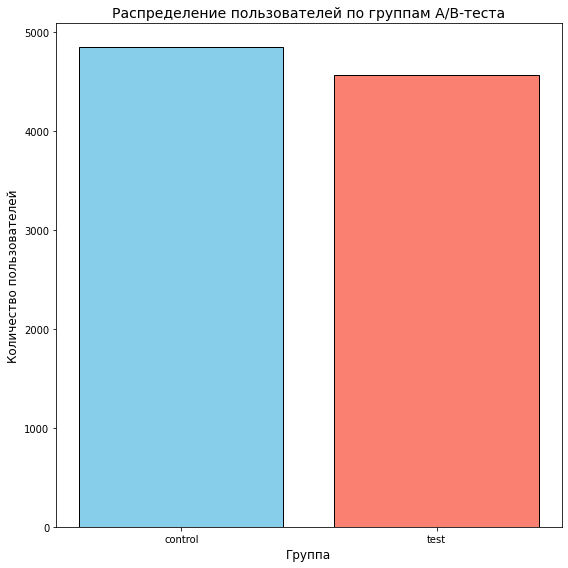

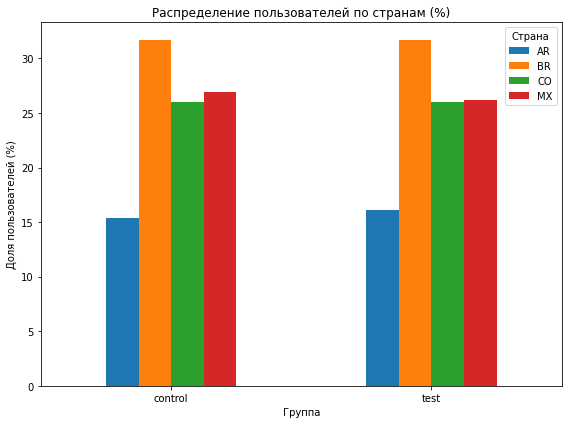

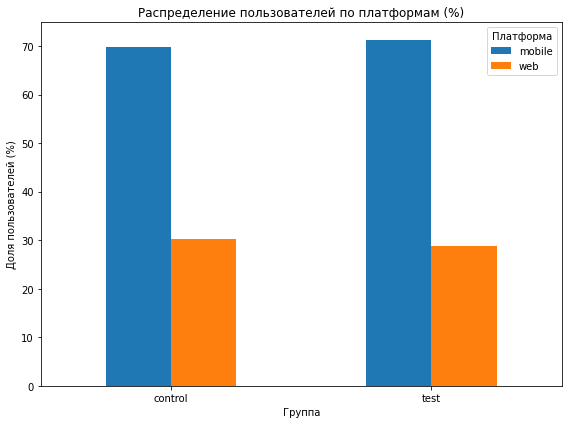

In [21]:
# Общее распределение по группам
group_counts = sollmafin_abt.groupby('group')['user_id'].nunique()

plt.figure(figsize=(8,8))
bars = plt.bar(group_counts.index, group_counts.values, color=['skyblue', 'salmon'], edgecolor='black')
plt.title('Распределение пользователей по группам A/B-теста', fontsize=14)
plt.xlabel('Группа', fontsize=12)
plt.ylabel('Количество пользователей', fontsize=12)
plt.tight_layout()
plt.show()

# Распределение по странам
country_groups = pd.crosstab(sollmafin_abt['group'], sollmafin_abt['country_code'], normalize='index') * 100

country_groups.plot(kind='bar', figsize=(8,6))
plt.title('Распределение пользователей по странам (%)')
plt.ylabel('Доля пользователей (%)')
plt.xlabel('Группа')
plt.legend(title='Страна')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Распределение по платформам
platform_groups = pd.crosstab(sollmafin_abt['group'], sollmafin_abt['platform'], normalize='index') * 100

platform_groups.plot(kind='bar', figsize=(8,6))
plt.title('Распределение пользователей по платформам (%)')
plt.ylabel('Доля пользователей (%)')
plt.xlabel('Группа')
plt.legend(title='Платформа')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Выводы**
- Группы сбалансированы по странам (разница ≤ 0.7%) и платформам (разница ≤ 1.5%).
- Пересечений между группами нет.
- Разница в размере групп: 4847 vs 4568 (~5.8%) - допустима для случайного распределения.
- Эксперимент проведён корректно, данные можно использовать для анализа.

**Задача 3.2.** Сравнение воронок событий.
- Сравните пользовательский путь новых пользователей в тестовой и контрольной группах.
- Постройте классическую и последовательную воронки, выполните визуализацию и сделайте промежуточный вывод. 

In [22]:
def build_funnel(df, group_name):
    group_df = df[df['group'] == group_name]
    funnel_steps = ['install / open_web', 'introduction', 'registration', 'main_page', 
                   'onboarding_complete', 'first_deposit', 'second_deposit']
    
    counts = []
    for step in funnel_steps:
        users = group_df[group_df['event_name'] == step]['user_id'].nunique()
        counts.append(users)
    
    funnel_data = pd.DataFrame({
        'step': funnel_steps,
        'users': counts
    })
    
    first_step_users = funnel_data['users'].iloc[0]
    funnel_data['conversion_from_first_%'] = (funnel_data['users'] / first_step_users * 100).round(1)
    funnel_data['conversion_from_previous_%'] = (funnel_data['users'] / funnel_data['users'].shift(1) * 100).round(1)
    
    return funnel_data

# Строим воронки для обеих групп
funnel_control = build_funnel(sollmafin_abt, 'control')
funnel_test = build_funnel(sollmafin_abt, 'test')

print("Контрольная группа:")
display(funnel_control)
print("\nТестовая группа:")
display(funnel_test)

Контрольная группа:


,step,users,conversion_from_first_%,conversion_from_previous_%
0,install / open_web,4847,100.0,NaN
1,introduction,4847,100.0,100.0
2,registration,4512,93.1,93.1
3,main_page,4161,85.8,92.2
4,onboarding_complete,4063,83.8,97.6
5,first_deposit,3228,66.6,79.4
6,second_deposit,654,13.5,20.3



Тестовая группа:


,step,users,conversion_from_first_%,conversion_from_previous_%
0,install / open_web,4568,100.0,NaN
1,introduction,4568,100.0,100.0
2,registration,4265,93.4,93.4
3,main_page,3919,85.8,91.9
4,onboarding_complete,3462,75.8,88.3
5,first_deposit,2987,65.4,86.3
6,second_deposit,974,21.3,32.6


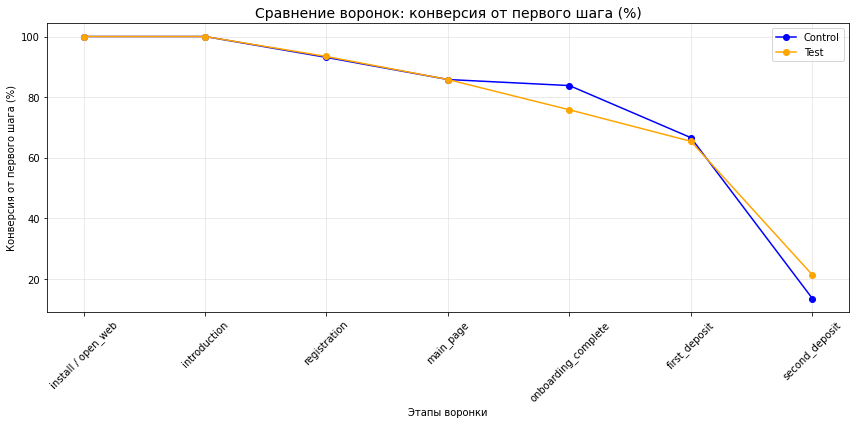

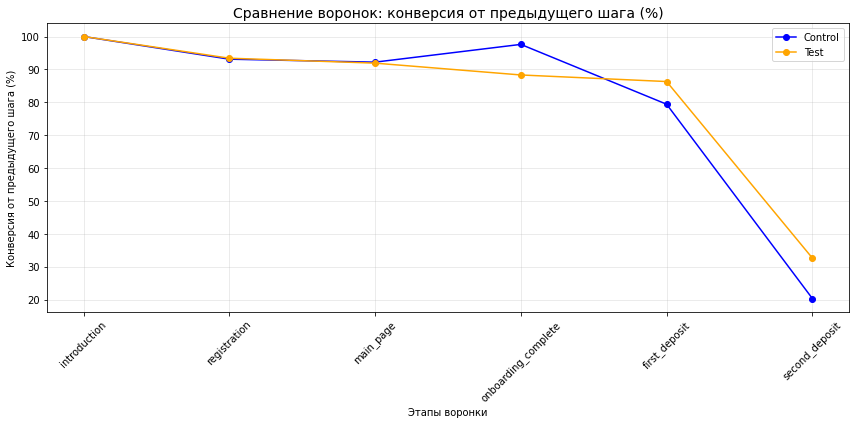

In [23]:
# Сравнение конверсии от первого шага
plt.figure(figsize=(12,6))
plt.plot(funnel_control['step'], funnel_control['conversion_from_first_%'], 'o-', label='Control', color='blue')
plt.plot(funnel_test['step'], funnel_test['conversion_from_first_%'], 'o-', label='Test', color='orange')
plt.title('Сравнение воронок: конверсия от первого шага (%)', fontsize=14)
plt.xlabel('Этапы воронки')
plt.ylabel('Конверсия от первого шага (%)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Сравнение конверсии от предыдущего шага
plt.figure(figsize=(12,6))
plt.plot(funnel_control['step'][1:], funnel_control['conversion_from_previous_%'][1:], 'o-', label='Control', color='blue')
plt.plot(funnel_test['step'][1:], funnel_test['conversion_from_previous_%'][1:], 'o-', label='Test', color='orange')
plt.title('Сравнение воронок: конверсия от предыдущего шага (%)', fontsize=14)
plt.xlabel('Этапы воронки')
plt.ylabel('Конверсия от предыдущего шага (%)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Выводы**
- Барьерная метрика (регистрация - первый депозит):
   - Контроль: 66.6% → Тест: 65.4% (падение на 1.2 п.п., не значимо)
- Вспомогательная 1 (первый - второй депозит):
   - Контроль: 20.3% → Тест: 32.6% (рост на 12.3 п.п., +60.9%)
- Гипотеза роста подтверждена: конверсия во второй депозит выросла значительно.
- Гипотеза риска НЕ подтверждена: падение конверсии в первый депозит не значимо.

**Задача 3.3.** Влияние новой фичи на конверсию во второй депозит с учётом уровня риска купленного актива.
- Проанализируйте, как категория риска купленного актива влияет на вероятность открытия второго депозита в тестовой и контрольной группах. 
- Сравните результаты и оцените, есть ли статистически значимая разница между группами. 

**Формулируем гипотезы:**
- H0 (нулевая гипотеза): Обучение в онбординге не влияет на конверсию во второй депозит для пользователей, выбравших активы с разным уровнем риска. Разница между контрольной и тестовой группами отсутствует.

- H1 (альтернативная гипотеза): Обучение в онбординге влияет на конверсию во второй депозит для пользователей, выбравших активы с разным уровнем риска. Разница между контрольной и тестовой группами существует.

In [24]:
# функция для рассчета конверсии от риска по группам
def analyze_risk_conversion(df, group_name):
    
    # Фильтруем по группе
    group_df = df[df['group'] == group_name] 
    
    # Находим первую покупку актива для каждого пользователя
    first_asset = (group_df[group_df['event_name'] == 'asset_purchase']
                   .sort_values('event_ts')
                   .drop_duplicates('user_id', keep='first')
                   [['user_id', 'risk_level']])
    
    # Находим пользователей со вторым депозитом
    second_deposit_users = (group_df[group_df['event_name'] == 'second_deposit']
                            ['user_id'].unique())
    
    # Добавляем флаг наличия второго депозита
    first_asset['has_second_deposit'] = first_asset['user_id'].isin(second_deposit_users)
    
    # Группируем по уровню риска
    conversion_by_risk = first_asset.groupby('risk_level').agg(
        total_users=('user_id', 'count'),
        users_with_second=('has_second_deposit', 'sum')
    )
    conversion_by_risk['conversion_%'] = (conversion_by_risk['users_with_second'] / 
                                          conversion_by_risk['total_users'] * 100).round(1)
    
    return conversion_by_risk

# Считаем для контрольной и тестовой групп
risk_control = analyze_risk_conversion(sollmafin_abt, 'control')
risk_test = analyze_risk_conversion(sollmafin_abt, 'test')

print("Контрольная группа:")
display(risk_control)
print("\nТестовая группа:")
display(risk_test)

# Объединяем для сравнения
risk_comparison = pd.DataFrame({
    'control': risk_control['conversion_%'],
    'test': risk_test['conversion_%']
})
risk_comparison['change_pp'] = (risk_comparison['test'] - risk_comparison['control']).round(1)
risk_comparison['change_%'] = ((risk_comparison['test'] / risk_comparison['control'] - 1) * 100).round(1)

# Добавляем p-value для каждого уровня риска
p_values = []
for risk in risk_control.index:
    count = [risk_control.loc[risk, 'users_with_second'], risk_test.loc[risk, 'users_with_second']]
    nobs = [risk_control.loc[risk, 'total_users'], risk_test.loc[risk, 'total_users']]
    _, p_val = proportions_ztest(count, nobs)
    p_values.append(round(p_val, 5))

risk_comparison['p_value'] = p_values
risk_comparison['Значимость'] = risk_comparison['p_value'] < 0.05

print("\nСравнение конверсий по риску:")
display(risk_comparison)

Контрольная группа:


,total_users,users_with_second,conversion_%
risk_level,,,
high,893,247,27.7
low,285,142,49.8
medium,595,265,44.5



Тестовая группа:


,total_users,users_with_second,conversion_%
risk_level,,,
high,737,339,46.0
low,496,285,57.5
medium,744,350,47.0



Сравнение конверсий по риску:


,control,test,change_pp,change_%,p_value,Значимость
risk_level,,,,,,
high,27.7,46.0,18.3,66.1,0.00000,True
low,49.8,57.5,7.7,15.5,0.03907,True
medium,44.5,47.0,2.5,5.6,0.36069,False


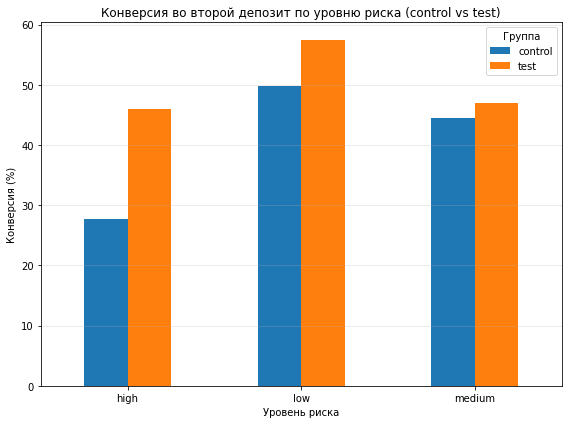

In [25]:
# График сравнения конверсий по уровню риска
risk_comparison[['control', 'test']].plot(kind='bar', figsize=(8,6))
plt.title('Конверсия во второй депозит по уровню риска (control vs test)')
plt.ylabel('Конверсия (%)')
plt.xlabel('Уровень риска')
plt.legend(title='Группа')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Выводы**
- Дополнительная гипотеза подтверждена:
   - High-risk: 27.7% - 46.0% (рост на 18.3 п.п., +66%, p < 0.001)
   - Low-risk: 49.8% - 57.5% (рост на 7.7 п.п., +15.5%, p = 0.039)
- Дополнительная гипотеза не подтверждена:
   - Medium-risk: 44.5% - 47.0% (рост на 2.5 п.п., +5.6%, p = 0.361)
- Наибольший эффект - у high-risk сегмента, самой проблемной зоны.

**Задача 3.4.** Анализ метрик А/В-эксперимента. Проанализируйте такие метрики:
- Ключевая метрика — средняя сумма всех депозитов на одного пользователя (включая тех, кто установил приложение или открыл веб-версию).
- Барьерная метрика — конверсия из регистрации в первый депозит.
- Вспомогательная метрика 1 — конверсия из первого депозита во второй.
- Вспомогательная метрика 2 — средняя сумма всех депозитов на пользователя, который открыл хотя бы один депозит.

Для каждой метрики выведите: 
- значения в контрольной и тестовой группах, 
- абсолютные и относительные изменения значений в тестовой группе по сравнению с контрольной.

После этого проверьте статистическую значимость различий метрик между группами эксперимента. 

Для ключевой метрики также изучите:
- накопленную динамику изменения по дням эксперимента для каждой группы, 
- стабильность p-value во время эксперимента.

Сделайте промежуточный вывод. 


In [26]:
# функция для рассчета метрик по группам
def calculate_metrics(df, group_name):
    
    # Фильтруем по группе
    group_df = df[df['group'] == group_name]
    
    # Общее количество пользователей
    total_users = group_df['user_id'].nunique()
    
    # Пользователи с регистрацией
    registered_users = group_df[group_df['event_name'] == 'registration']['user_id'].nunique()
    
    # Пользователи с первым депозитом
    first_deposit_users = group_df[group_df['event_name'] == 'first_deposit']['user_id'].nunique()
    
    # Пользователи со вторым депозитом
    second_deposit_users = group_df[group_df['event_name'] == 'second_deposit']['user_id'].nunique()
    
    # Сумма всех депозитов
    deposit_sum = group_df[group_df['event_name'].isin(['first_deposit', 'second_deposit'])]['amount'].sum()
    
    # Метрики
    key_metric = deposit_sum / total_users  # на всех пользователей
    barrier_metric = (first_deposit_users / registered_users * 100) if registered_users > 0 else 0  # конверсия в первый депозит
    auxiliary_1 = (second_deposit_users / first_deposit_users * 100) if first_deposit_users > 0 else 0  # конверсия 1-2
    auxiliary_2 = deposit_sum / first_deposit_users if first_deposit_users > 0 else 0  # средний чек на платящего
    
    return {
        'total_users': total_users,
        'registered_users': registered_users,
        'first_deposit_users': first_deposit_users,
        'second_deposit_users': second_deposit_users,
        'deposit_sum': deposit_sum,
        'key_metric': key_metric,
        'barrier_metric': barrier_metric,
        'auxiliary_1': auxiliary_1,
        'auxiliary_2': auxiliary_2
    }

# Рассчитываем для обеих групп
metrics_control = calculate_metrics(sollmafin_abt, 'control')
metrics_test = calculate_metrics(sollmafin_abt, 'test')

# Создаём DataFrame для сравнения
comparison_df = pd.DataFrame({
    'Метрика': ['Ключевая (средняя сумма на пользователя)', 
                'Барьерная (конверсия в первый депозит, %)', 
                'Вспомогательная 1 (конверсия 1-2, %)', 
                'Вспомогательная 2 (средний чек на платящего)'],
    'Контроль': [metrics_control['key_metric'], 
                 metrics_control['barrier_metric'], 
                 metrics_control['auxiliary_1'], 
                 metrics_control['auxiliary_2']],
    'Тест': [metrics_test['key_metric'], 
             metrics_test['barrier_metric'], 
             metrics_test['auxiliary_1'], 
             metrics_test['auxiliary_2']]
})

comparison_df['Абсолютное изменение'] = comparison_df['Тест'] - comparison_df['Контроль']
comparison_df['Относительное изменение (%)'] = ((comparison_df['Тест'] / comparison_df['Контроль'] - 1) * 100).round(1)

display(comparison_df)

,Метрика,Контроль,Тест,Абсолютное изменение,Относительное изменение (%)
0,Ключевая (средняя сумма на пользователя),90.240149,92.460814,2.220666,2.5
1,"Барьерная (конверсия в первый депозит, %)",71.542553,70.035170,-1.507383,-2.1
2,"Вспомогательная 1 (конверсия 1-2, %)",20.260223,32.607968,12.347745,60.9
3,Вспомогательная 2 (средний чек на платящего),135.500000,141.399732,5.899732,4.4


In [27]:
# Функция получения суммы депозитов пользователей
def get_user_deposits(df, group_name):
    
    # Фильтруем по группе
    group_df = df[df['group'] == group_name]
    
    # Сумма всех депозитов
    deposits = group_df[group_df['event_name'].isin(['first_deposit', 'second_deposit'])].groupby('user_id')['amount'].sum()
    
    # Список всех пользователей
    all_users = group_df['user_id'].unique()

    # Превращаем сумму депозитов в словарь
    deposit_dict = deposits.to_dict()
    
    return np.array([deposit_dict.get(user, 0) for user in all_users])

print("Проверка статистической значимости\n")

# Ключевая метрика
control_deposits = get_user_deposits(sollmafin_abt, 'control')
test_deposits = get_user_deposits(sollmafin_abt, 'test')
_, p_key = ttest_ind(control_deposits, test_deposits, equal_var=False)
print(f"Ключевая метрика: p-value = {p_key:.4f} → {'Значимо' if p_key < 0.05 else 'Не значимо'}")

# Барьерная метрика
_, p_barrier = proportions_ztest(
    [metrics_control['first_deposit_users'], metrics_test['first_deposit_users']],
    [metrics_control['registered_users'], metrics_test['registered_users']]
)
print(f"Барьерная метрика: p-value = {p_barrier:.4f} → {'Значимо' if p_barrier < 0.05 else 'Не значимо'}")

# Вспомогательная метрика 1
_, p_aux1 = proportions_ztest(
    [metrics_control['second_deposit_users'], metrics_test['second_deposit_users']],
    [metrics_control['first_deposit_users'], metrics_test['first_deposit_users']]
)
print(f"Вспомогательная 1: p-value = {p_aux1:.4f} → {'Значимо' if p_aux1 < 0.05 else 'Не значимо'}")

# Вспомогательная метрика 2
control_paying = control_deposits[control_deposits > 0]
test_paying = test_deposits[test_deposits > 0]
_, p_paying = ttest_ind(control_paying, test_paying, equal_var=False)
print(f"Вспомогательная 2: p-value = {p_paying:.4f} → {'Значимо' if p_paying < 0.05 else 'Не значимо'}")

Проверка статистической значимости

Ключевая метрика: p-value = 0.3383 → Не значимо
Барьерная метрика: p-value = 0.1205 → Не значимо
Вспомогательная 1: p-value = 0.0000 → Значимо
Вспомогательная 2: p-value = 0.0400 → Значимо


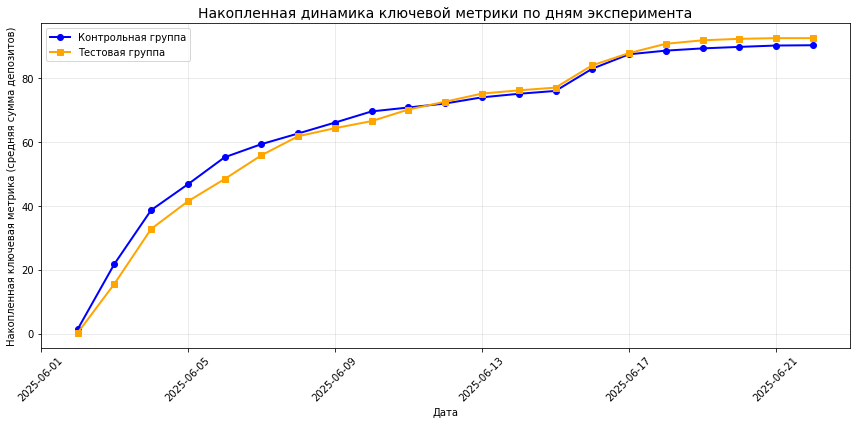

In [28]:
sollmafin_abt['event_dt'] = sollmafin_abt['event_ts'].dt.date

# Суммируем депозиты по дням, пользователям и группам
daily_deposits = sollmafin_abt[sollmafin_abt['event_name'].isin(['first_deposit', 'second_deposit'])].groupby(['event_dt', 'user_id', 'group'])['amount'].sum().reset_index()

# Все уникальные даты активности
activity_dates = sorted(daily_deposits['event_dt'].unique())

cumulative_control = []
cumulative_test = []
p_values_cumulative = []

for date in activity_dates:
    # Фильтруем депозиты до этой даты включительно
    control_deposits = daily_deposits[(daily_deposits['group'] == 'control') & (daily_deposits['event_dt'] <= date)]
    test_deposits = daily_deposits[(daily_deposits['group'] == 'test') & (daily_deposits['event_dt'] <= date)]
    
    # Получаем всех пользователей
    control_users = sollmafin_abt[(sollmafin_abt['group'] == 'control') & (sollmafin_abt['first_dt'].dt.date <= date)]['user_id'].unique()
    test_users = sollmafin_abt[(sollmafin_abt['group'] == 'test') & (sollmafin_abt['first_dt'].dt.date <= date)]['user_id'].unique()
    
    # Суммы депозитов по пользователям
    control_dict = control_deposits.groupby('user_id')['amount'].sum().to_dict()
    test_dict = test_deposits.groupby('user_id')['amount'].sum().to_dict()
    
    control_amounts = np.array([control_dict.get(user, 0) for user in control_users])
    test_amounts = np.array([test_dict.get(user, 0) for user in test_users])
    
    # Ключевая метрика
    cumulative_control.append(control_amounts.mean())
    cumulative_test.append(test_amounts.mean())
    
    # p-value для t-теста
    if len(control_amounts) > 1 and len(test_amounts) > 1:
        _, p_val = ttest_ind(control_amounts, test_amounts, equal_var=False)
        p_values_cumulative.append(p_val)
    else:
        p_values_cumulative.append(np.nan)

# Визуализация
plt.figure(figsize=(12,6))
plt.plot(activity_dates, cumulative_control, 'o-', label='Контрольная группа', color='blue', linewidth=2)
plt.plot(activity_dates, cumulative_test, 's-', label='Тестовая группа', color='orange', linewidth=2)
plt.xlabel('Дата')
plt.ylabel('Накопленная ключевая метрика (средняя сумма депозитов)')
plt.title('Накопленная динамика ключевой метрики по дням эксперимента', fontsize=14)
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

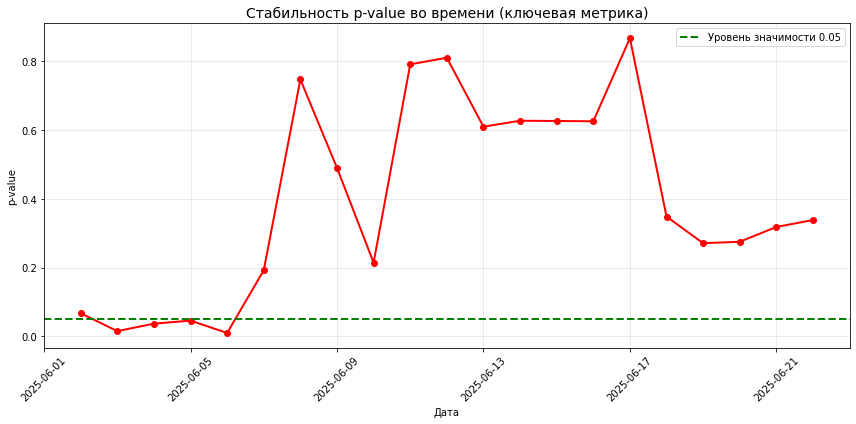

In [29]:
plt.figure(figsize=(12,6))
plt.plot(activity_dates, p_values_cumulative, 'o-', color='red', linewidth=2)
plt.axhline(y=0.05, color='green', linestyle='--', linewidth=2, label='Уровень значимости 0.05')
plt.xlabel('Дата')
plt.ylabel('p-value')
plt.title('Стабильность p-value во времени (ключевая метрика)', fontsize=14)
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Выводы**
- Ключевая метрика: 90.24 - 92.46 (+2.5%, p=0.34 → не значимо)
- Барьерная метрика: 71.54% - 70.04% (-2.1%, p=0.12 → не значимо)
- Вспомогательная 1: 20.26% - 32.61% (+60.9%, p<0.001 → значимо)
- Вспомогательная 2: 135.50 - 141.40 (+4.4%, p=0.04 → значимо)

- Накопленная динамика: тестовая группа выходит вперёд к концу эксперимента.
- p-value остаётся > 0.05 на протяжении всего эксперимента, что подтверждает отсутствие статистически значимого эффекта на ключевую метрику.

---

### 4. Анализ изменений суммы депозитов на платящего пользователя

Новая фича могла повлиять на поведение пользователей.
- Пользователи, которые раньше вносили небольшие суммы, могли стать более осторожными, сократить свои вложения или совсем перестать платить. Это отразится в снижении 25-го перцентиля суммы депозитов в тестовой группе.
- Пользователи, которые склонны к более крупным инвестициям, могли сильнее вовлечься в продукт и начать вносить больше средств. Это отразится в росте 75-го перцентиля.

Используя бутстрап, сравните разницы перцентилей (25, 50, 75) суммы всех депозитов на платящего пользователя в контрольной и тестовой группах:
- Постройте доверительные интервалы для разницы между группами для каждого перцентиля.
- Интерпретируйте изменения в контексте сформулированной выше гипотезы.
- Визуализируйте результат бутстрап-теста. 

Платящих пользователей в контрольной группе: 3228
Платящих пользователей в тестовой группе: 2987
25-й перцентиль:
  Контроль: 95.00
  Тест: 48.00
  Разница (тест - контроль): -47.00
  95% ДИ разницы: [-50.00, -44.00]
  Значимое падение

50-й перцентиль:
  Контроль: 118.00
  Тест: 94.00
  Разница (тест - контроль): -24.00
  95% ДИ разницы: [-27.00, -19.00]
  Значимое падение

75-й перцентиль:
  Контроль: 159.00
  Тест: 179.50
  Разница (тест - контроль): 20.50
  95% ДИ разницы: [11.00, 30.00]
  Значимый рост



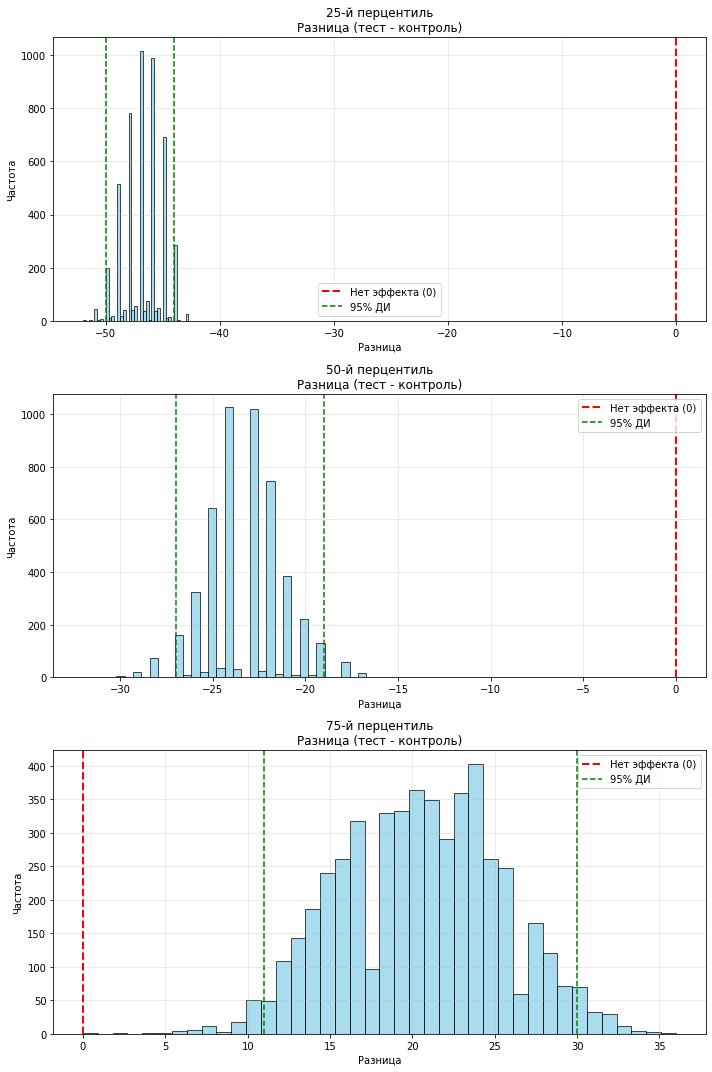

In [30]:
# Получаем данные для платящих пользователей
def get_paying_user_deposits(df, group_name):
    group_df = df[df['group'] == group_name]
    paying_users = group_df[group_df['event_name'] == 'first_deposit']['user_id'].unique()
    deposits = group_df[group_df['event_name'].isin(['first_deposit', 'second_deposit'])].groupby('user_id')['amount'].sum()
    return np.array([deposits.get(user, 0) for user in paying_users])

control_paying = get_paying_user_deposits(sollmafin_abt, 'control')
test_paying = get_paying_user_deposits(sollmafin_abt, 'test')

print(f"Платящих пользователей в контрольной группе: {len(control_paying)}")
print(f"Платящих пользователей в тестовой группе: {len(test_paying)}")

# Бутстрап для перцентилей
np.random.seed(341)  # Фиксируем сид для воспроизводимости

n_iterations = 5000
percentiles = [25, 50, 75]

boot_diffs = {p: [] for p in percentiles}

# Основной цикл бутстрапа
for i in range(n_iterations):
    # Сэмплируем с возвращением
    boot_control = np.random.choice(control_paying, size=len(control_paying), replace=True)
    boot_test = np.random.choice(test_paying, size=len(test_paying), replace=True)
    
    # Считаем перцентили для каждой бутстрап-выборки
    for p in percentiles:
        control_p = np.percentile(boot_control, p)
        test_p = np.percentile(boot_test, p)
        boot_diffs[p].append(test_p - control_p)

# Анализ результатов

for p in percentiles:
    diffs = np.array(boot_diffs[p])
    
    # Фактические перцентили в группах
    control_p = np.percentile(control_paying, p)
    test_p = np.percentile(test_paying, p)
    
    # Доверительный интервал
    diff_ci = np.percentile(diffs, [2.5, 97.5])
    
    print(f"{p}-й перцентиль:")
    print(f"  Контроль: {control_p:.2f}")
    print(f"  Тест: {test_p:.2f}")
    print(f"  Разница (тест - контроль): {test_p - control_p:.2f}")
    print(f"  95% ДИ разницы: [{diff_ci[0]:.2f}, {diff_ci[1]:.2f}]")
    
    if diff_ci[0] > 0:
        print(f"  Значимый рост")
    elif diff_ci[1] < 0:
        print(f"  Значимое падение")
    else:
        print(f"  Изменение не значимо")
    print()

# Визуализация распределений разниц
fig, axes = plt.subplots(3, 1, figsize=(10, 15))

for idx, p in enumerate(percentiles):
    diffs = np.array(boot_diffs[p])
    
    axes[idx].hist(diffs, bins=40, edgecolor='black', alpha=0.7, color='skyblue')
    axes[idx].axvline(x=0, color='red', linestyle='--', linewidth=2, label='Нет эффекта (0)')
    axes[idx].axvline(x=np.percentile(diffs, 2.5), color='green', linestyle='--', linewidth=1.5, label='95% ДИ')
    axes[idx].axvline(x=np.percentile(diffs, 97.5), color='green', linestyle='--', linewidth=1.5)
    
    axes[idx].set_title(f'{p}-й перцентиль\nРазница (тест - контроль)', fontsize=12)
    axes[idx].set_xlabel('Разница')
    axes[idx].set_ylabel('Частота')
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Выводы**

- 25-й перцентиль: 95.00 - 48.00 (-47.00, ДИ [-50, -44]) - значимое падение
- 50-й перцентиль (медиана): 118.00 - 94.00 (-24.00, ДИ [-27, -19]) - значимое падение
- 75-й перцентиль: 159.00 - 179.50 (+20.50, ДИ [11, 30]) - значимый рост

**Интерпретация:**
- Нижние и средние пользователи стали вкладывать меньше (испугались рисков)
- Верхние 25% пользователей стали вкладывать больше (лучше вовлеклись)
- Распределение депозитов стало более поляризованным
- Снижение медианы - это побочный эффект успешного обучения, а не признак провала фичи. Пользователи стали более осознанными, но по-разному отреагировали на информацию о рисках в зависимости от своего психотипа и склонности к риску.

---

### 5. Выводы

Сформулируйте общий вывод. Зафиксируйте основные результаты и инсайты, которые, на ваш взгляд, помогут бизнесу улучшить продукт. Опишите, как новая фича повлияла на продукт: подтвердилась ли гипотеза, что делать дальше и есть ли риски. Объясните, какие результаты значимы и почему. 

Вывод предназначен для вашего заказчика и менеджеров продукта, поэтому сделайте его кратким, содержательным и понятным. 

**Основные результаты:**
- Ключевой результат эксперимента - конверсия из первого депозита во второй выросла на 60.9% (с 20.3% до 32.6%). Этот рост статистически значим (p < 0.001) и является главным подтверждением эффективности новой фичи.
- Средний чек платящего пользователя также вырос на 4.4% (с 135.5 до 141.4), что статистически значимо (p = 0.04). Это означает, что пользователи, которые остались в продукте, стали вкладывать больше.
- При этом конверсия в первый депозит снизилась всего на 2.1% (с 71.5% до 70.0%), но это падение не является статистически значимым (p = 0.12). Таким образом, гипотеза о том, что обучение отпугнёт пользователей от первого депозита, не подтвердилась.
- Средняя сумма депозитов на одного пользователя выросла на 2.5% (с 90.2 до 92.5), однако этот рост также не является статистически значимым (p = 0.34). Это связано с тем, что часть пользователей сократила свои вложения, что компенсировало положительный эффект от роста конверсии.

**Влияние в разрезе сегментов:**
- Наиболее сильный эффект зафиксирован у пользователей, выбирающих высокорисковые активы. Их конверсия во второй депозит выросла с 27.7% до 46.0% (+66%). Это ключевой сегмент, который раньше был самой проблемной зоной, и именно здесь обучение дало максимальный результат.
- Однако важно отметить побочный эффект - поляризацию депозитов.
- Пользователи с небольшими вложениями (25-й перцентиль) сократили депозиты с 95 до 48, а пользователи с крупными вложениями (75-й перцентиль) увеличили их с 159 до 179.5. Это говорит о том, что информация о рисках по-разному повлияла на разные сегменты: осторожные пользователи стали вкладывать меньше, а уверенные - больше.

**Рекомендации:**
- Внедрять новую фичу - эффект положительный, стабильный и статистически подтверждённый.
- Доработать онбординг для осторожных пользователей - они услышали предупреждение о рисках и сократили вложения. Можно добавить мягкие подсказки или персонализированные рекомендации по выбору активов.
- Усилить работу с high-risk сегментом - именно там самый сильный эффект. Предлагать этим пользователям дополнительные обучающие материалы или премиум-функции.
- Продолжить мониторинг - отслеживать долгосрочный эффект и влияние на LTV пользователей.

**Риски:**
- Основной риск - поляризация пользователей: осторожные пользователи стали вкладывать меньше, а крупные - больше. Это может привести к снижению общего дохода от массового сегмента.
- Рекомендация: не отказываться от фичи, но добавить механики удержания осторожных пользователей, например, персонализированные рекомендации или адаптивный онбординг.

**Резюме:**
- Новая фича работает. Конверсия во второй депозит выросла на 60.9%, средний чек платящих - на 4.4%, при этом конверсия в первый депозит не пострадала. Основной риск - сокращение вложений у осторожных пользователей - требует доработки, но не является причиной для отказа от внедрения.

- Рекомендуем внедрять фичу и параллельно работать над персонализацией онбординга для разных сегментов.